# 03 — Probabilistic models on the base features

**Question.** Do quantile models on the base feature set beat the vendor baselines, and are their quantiles
calibrated?

Runs 004 and 005 of the 20-run budget fit one model per quantile τ ∈ {0.1, …, 0.9} on `BASE_FEATURES`:
capacity-corrected vendor DA (onshore, offshore, total), DA total ramps (Δ1h, Δ3h), hour of day, day of year
(sin/cos), and the 7-day mean error and MAE of the corrected vendor forecast as of the issue-time cutoff.

| run | model |
|---|---|
| `004_linear_qr` | linear quantile regression (scikit-learn, HiGHS, no penalty; stride subsample of ≤ 6,000 training rows) |
| `005_lgbm` | LightGBM, objective `quantile`, library default hyper-parameters |

Same frozen evaluation as notebook 02: 4 folds, 8,580 scored hours, refit before each fold. Only delivery days
before 2026-05-01 are used.

**Acceptance rule** (fixed before run 001): the first non-baseline run becomes the current best only if its mean
P10–P90 coverage is within 76–84%; later runs must also cut mean CRPS by ≥ 1%, improve CRPS on ≥ 3 of 4 folds and
not worsen P50 MAE by > 1%.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from windfc.cutoff import delivery_day
from windfc.evaluate import TEST_PERIOD
from windfc.notebook import load_validation
from windfc.run import REPO_ROOT as ROOT

TEST_START = pd.Timestamp(TEST_PERIOD[0])
FIG_DIR = ROOT / "docs" / "figures"
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "lines.linewidth": 1.6, "legend.frameon": False,
})
# Fixed series colours (validated categorical slots 1-3, then neutral ink).
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "ink": "#0b0b0b", "grey": "#8a8984"}

# Validation-only data (windfc.notebook.load_validation): hours whose Danish local
# delivery day is before the locked test period; test rows are filtered while reading.
df = load_validation()
dday = delivery_day(df.index)
assert dday.max() < TEST_START  # also asserted inside load_validation
print(f"hours {df.index.min()} .. {df.index.max()} UTC; delivery days {dday.min().date()} .. {dday.max().date()}")

hours 2021-12-31 23:00:00 .. 2026-04-30 21:00:00 UTC; delivery days 2022-01-01 .. 2026-04-30


In [2]:
from windfc.notebook import fold_table, rerun
from windfc.run import read_log

LOG = ROOT / "experiments" / "log.csv"
CONFIGS = ROOT / "experiments" / "configs"
log = read_log(LOG)  # read only; rerun() writes to a temp log and refuses this path

## 1. The log after five runs

In [3]:
show = log[["run_id", "crps_f1", "crps_f2", "crps_f3", "crps_f4", "crps_mean", "mae_p50_mean",
            "coverage_mean", "bias_mean", "decision", "reason"]].set_index("run_id")
show.round(3)

,crps_f1,crps_f2,crps_f3,crps_f4,crps_mean,mae_p50_mean,coverage_mean,bias_mean,decision,reason
run_id,,,,,,,,,,
001_persistence,347.252,366.117,513.364,424.288,412.755,1068.248,0.792,-28.319,baseline,baseline model; not eligible as current best
002_vendor_raw,122.905,122.281,130.880,100.825,119.223,299.586,0.773,-4.294,baseline,baseline model; not eligible as current best
003_vendor_capacity,124.344,123.041,132.508,103.050,120.736,303.013,0.778,15.298,baseline,baseline model; not eligible as current best
004_linear_qr,112.467,121.799,123.813,108.470,116.637,296.271,0.778,-38.027,accepted,initial best
005_lgbm,109.745,121.160,104.393,99.409,108.677,274.076,0.693,-25.604,rejected,"coverage_mean 0.693 outside [0.76, 0.84]"


## 2. Per-fold comparison

Re-run (throwaway log, logged CRPS reproduced) to get per-fold metrics and predictions.

In [4]:
runs = ["002_vendor_raw", "003_vendor_capacity", "004_linear_qr", "005_lgbm"]
res = {rid: rerun(CONFIGS / f"{rid}.yaml") for rid in runs}
ft = fold_table(res.values())
ft.pivot(index="fold", columns="run", values="crps").round(2)

run,002_vendor_raw,003_vendor_capacity,004_linear_qr,005_lgbm
fold,,,,
1,122.91,124.34,112.47,109.74
2,122.28,123.04,121.80,121.16
3,130.88,132.51,123.81,104.39
4,100.82,103.05,108.47,99.41


In [5]:
wide = {k: ft.pivot(index="fold", columns="run", values=k) for k in ["crps", "mae_p50", "coverage_80", "bias"]}
summary = pd.DataFrame({k: v.mean() for k, v in wide.items()})
summary["CRPS vs 002 %"] = 100 * (summary.crps / summary.loc["002_vendor_raw", "crps"] - 1)
summary["folds better than 002"] = (wide["crps"].lt(wide["crps"]["002_vendor_raw"], axis=0)).sum()
summary.round(3)

,crps,mae_p50,coverage_80,bias,CRPS vs 002 %,folds better than 002
run,,,,,,
002_vendor_raw,119.223,299.586,0.773,-4.294,0.000,0
003_vendor_capacity,120.736,303.013,0.778,15.298,1.269,0
004_linear_qr,116.637,296.271,0.778,-38.027,-2.168,3
005_lgbm,108.677,274.076,0.693,-25.604,-8.846,4


In [6]:
pd.concat({"coverage_80": wide["coverage_80"], "bias (P50 - actual)": wide["bias"]}, axis=1).round(3)

coverage_80                                            bias (P50 - actual)                                           
run  002_vendor_raw 003_vendor_capacity 004_linear_qr 005_lgbm      002_vendor_raw 003_vendor_capacity 004_linear_qr 005_lgbm
fold                                                                                                                         
1             0.769               0.769         0.749    0.684             146.588             146.415        10.263  -27.413
2             0.795               0.815         0.767    0.674              -4.074              36.074         5.123   16.899
3             0.726               0.741         0.759    0.691            -173.626            -171.831      -135.398  -87.967
4             0.801               0.787         0.836    0.721              13.936              50.534       -32.096   -3.934

**Reading.**

- **LightGBM (005)** has the lowest CRPS on every fold: mean 108.7 MWh, 8.8% below the raw vendor baseline, and
  P50 MAE 274 vs 300 MWh. Its largest gain is fold 3 (Nov–Jan, −20% CRPS), where the vendor baselines carry a
  fold-level P50 bias of about −174 MWh; LightGBM halves it (−88 MWh), consistent with the 7-day error features
  letting the model follow a seasonal bias that the 90-day offsets of the baselines lag.
  But its P10–P90 interval covers only 67–72% of actuals per fold (mean 69%), well below the 80% target, so the
  acceptance rule rejects it.
- **Linear QR (004)** is 2.2% better than the raw vendor on mean CRPS with valid coverage (78%) and becomes the
  initial current best. The gain is uneven: large on fold 1 (−8.5%), negligible on fold 2 (−0.4%), −5.4% on
  fold 3, and 7.6% *worse* on fold 4 (Feb–Apr 2026). It also removes the fold-1 bias of the baselines
  (+10 vs +147 MWh).

## 3. Reliability: are the quantiles calibrated?

For each nominal level τ, the share of actuals at or below the predicted τ-quantile, pooled over the four folds
(8,580 hours). A calibrated forecast lies on the diagonal.

In [7]:
from windfc.evaluate import QCOLS
from windfc import QUANTILES

models = {"003_vendor_capacity": C["blue"], "004_linear_qr": C["orange"], "005_lgbm": C["aqua"]}
rel = pd.DataFrame({rid: [(res[rid]["predictions"]["actual_total"] <= res[rid]["predictions"][q]).mean()
                          for q in QCOLS] for rid in models}, index=pd.Index(QUANTILES, name="nominal τ"))
rel.round(3)

,003_vendor_capacity,004_linear_qr,005_lgbm
nominal τ,,,
0.1,0.116,0.103,0.132
0.2,0.210,0.184,0.226
0.3,0.306,0.266,0.301
0.4,0.403,0.356,0.381
0.5,0.499,0.460,0.466
0.6,0.598,0.553,0.548
0.7,0.699,0.655,0.631
0.8,0.799,0.765,0.716
0.9,0.894,0.880,0.825


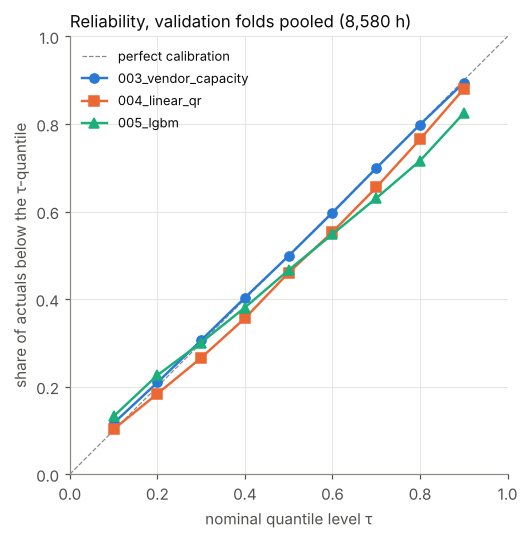

In [8]:
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 1], [0, 1], color=C["grey"], lw=0.8, ls="--", label="perfect calibration")
for (rid, colour), marker in zip(models.items(), ["o", "s", "^"]):
    ax.plot(rel.index, rel[rid], color=colour, marker=marker, ms=6, label=rid)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
ax.set_xlabel("nominal quantile level τ")
ax.set_ylabel("share of actuals below the τ-quantile")
ax.set_title("Reliability, validation folds pooled (8,580 h)", loc="left", fontsize=11)
ax.legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
plt.show()

**Reading.**

- The **vendor-capacity baseline** is close to the diagonal at every level (within 1.6 points); empirical error
  quantiles are calibrated by construction when errors are stable.
- **Linear QR** lies below the diagonal from τ = 0.2 upward (e.g. 46% of actuals below its P50): its quantiles are
  shifted down, i.e. it under-forecasts slightly (mean P50 bias −38 MWh), while its interval width is about right.
- **LightGBM** is too narrow in the tails: 13.2% of actuals fall below its P10 and 17.5% above its P90 (targets
  10% and 10%). The upper tail is the larger miss — actual output exceeds its P90 too often — and its centre is
  also shifted slightly low (46.6% below P50).

## 4. Example week: fan chart

Second full week (Monday–Sunday, Danish local days) of fold 3, chosen by that rule before plotting. Model: LightGBM
(005), as fit for fold 3 (trained on delivery days before 2025-11-01). The raw vendor DA total is shown for
reference.

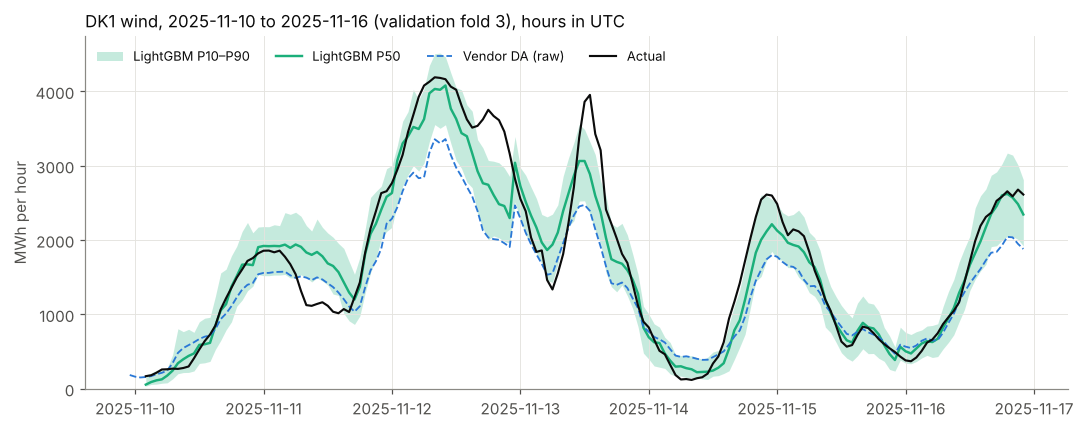

hours shown 165; P10-P90 coverage this week 0.78


In [9]:
from windfc.evaluate import period_mask

wk_start, wk_end = "2025-11-10", "2025-11-16"
p = res["005_lgbm"]["predictions"]
p = p[period_mask(p.index, wk_start, wk_end)]
vendor = df["da_total"][period_mask(df.index, wk_start, wk_end)]
assert (p.fold == 3).all() and len(p) > 0

fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(p.index, p.q10, p.q90, color=C["aqua"], alpha=0.25, lw=0, label="LightGBM P10–P90")
ax.plot(p.index, p.q50, color=C["aqua"], label="LightGBM P50")
ax.plot(vendor.index, vendor.values, color=C["blue"], lw=1.2, ls="--", label="Vendor DA (raw)")
ax.plot(p.index, p.actual_total, color=C["ink"], lw=1.4, label="Actual")
ax.set_ylabel("MWh per hour")
ax.set_ylim(bottom=0)
ax.set_title(f"DK1 wind, {wk_start} to {wk_end} (validation fold 3), hours in UTC", loc="left", fontsize=11)
ax.legend(loc="upper left", ncol=4, fontsize=8.5)
fig.tight_layout()
plt.show()
cov = ((p.q10 <= p.actual_total) & (p.actual_total <= p.q90)).mean()
print(f"hours shown {len(p)}; P10-P90 coverage this week {cov:.2f}")

## 5. Interpretation

- On the base features, LightGBM scores 8.8% lower mean CRPS than the raw vendor baseline and is lower on all four
  folds (significance not yet tested; rejected for under-coverage). This is validation evidence only; the locked test period has
  not been touched.
- That gain is not yet usable: LightGBM's 80% interval covers about 69% of outcomes, and mostly misses on the
  upside. (In the example week the band happens to cover 78% of hours; one week is illustration, not evidence.)
  A likely explanation (not tested here): with default settings (100 trees of 31 leaves, minimum 20 rows per leaf) each quantile model fits
  the training data closely, so the tail quantiles learned in-sample are too narrow out of sample. The acceptance
  rule rejects the run, as designed.
- Linear QR has valid interval coverage (78%; quantiles shifted slightly low) and is the current best (CRPS 116.6),
  but with a small, uneven gain and a loss on fold 4.
- **Implication for the optimization loop:** the natural candidates are conformalized quantile regression (CQR) on
  LightGBM, which widens the intervals by an amount measured on a recent hold-out window, and more regularised
  LightGBM settings (`min_child_samples`, `num_leaves`, `learning_rate`). Runs 006+ are documented in notebook 04.